<a href="https://colab.research.google.com/github/qcheng1-prog/market-tracer-app/blob/main/DM_Prediction_Spotify_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression


In [ ]:
url = "https://webpages.charlotte.edu/qcheng1/tbox/3162/data/songs-ori.csv"
df = pd.read_csv(url)

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

url = "https://webpages.charlotte.edu/qcheng1/tbox/3162/data/songs-ori.csv"
df = pd.read_csv(url)

# 1. Standardize features
scaler = StandardScaler()
numerical_features = df.select_dtypes(
    include=np.number
).columns.tolist()
x=df[numerical_features]
X_scaled = scaler.fit_transform(x)

# 2. Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# 3. Variance explained by each component
explained_variance = pca.explained_variance_ratio_

print("Variance explained:")
for i, variance in enumerate(explained_variance, 1):
    print(f"PC{i}: {variance:.2%}")

# 4. Cumulative variance
cumulative_variance = explained_variance.cumsum()

print("\nCumulative variance:")
for i, variance in enumerate(cumulative_variance, 1):
    print(f"PC1-PC{i}: {variance:.2%}")

#visualize PCA results in three complementary ways, because each answers a different question:

#1. How much information did we retain? → explained-variance plot
#2. What do the components mean? → loading plot
#3. What does the transformed data look like? → PC1–PC2 scatter plot

Variance explained:
PC1: 26.99%
PC2: 11.72%
PC3: 9.59%
PC4: 7.85%
PC5: 7.40%
PC6: 6.23%
PC7: 6.14%
PC8: 5.66%
PC9: 5.01%
PC10: 4.15%
PC11: 3.39%
PC12: 2.30%
PC13: 1.99%
PC14: 0.83%
PC15: 0.76%

Cumulative variance:
PC1-PC1: 26.99%
PC1-PC2: 38.71%
PC1-PC3: 48.30%
PC1-PC4: 56.15%
PC1-PC5: 63.55%
PC1-PC6: 69.78%
PC1-PC7: 75.92%
PC1-PC8: 81.58%
PC1-PC9: 86.59%
PC1-PC10: 90.74%
PC1-PC11: 94.13%
PC1-PC12: 96.43%
PC1-PC13: 98.42%
PC1-PC14: 99.24%
PC1-PC15: 100.00%


Visualize PCA results in three complementary ways, because each answers a different question:

1. How much information did we retain? → explained-variance plot
2. What do the components mean? → loading plot
3. What does the transformed data look like? → PC1–PC2 scatter plot

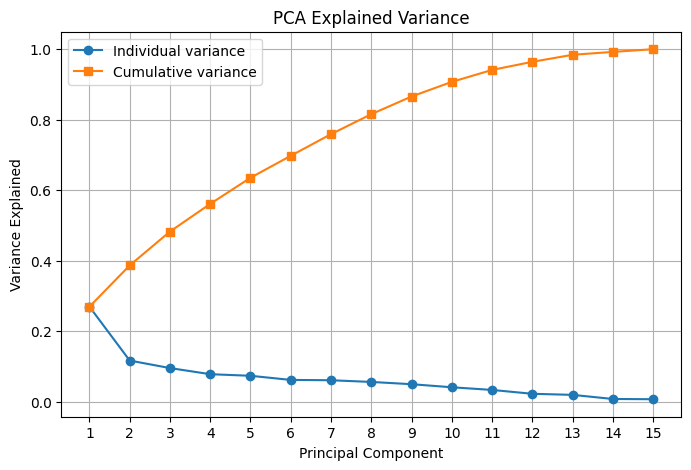

In [ ]:
# Explained Variance Plot — “How many PCs do we need?”

import matplotlib.pyplot as plt
import numpy as np

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained) + 1),
    explained,
    marker="o",
    label="Individual variance"
)

plt.plot(
    range(1, len(cumulative) + 1),
    cumulative,
    marker="s",
    label="Cumulative variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Variance Explained")
plt.title("PCA Explained Variance")
plt.xticks(range(1, len(explained) + 1))
plt.legend()
plt.grid(True)

plt.show()

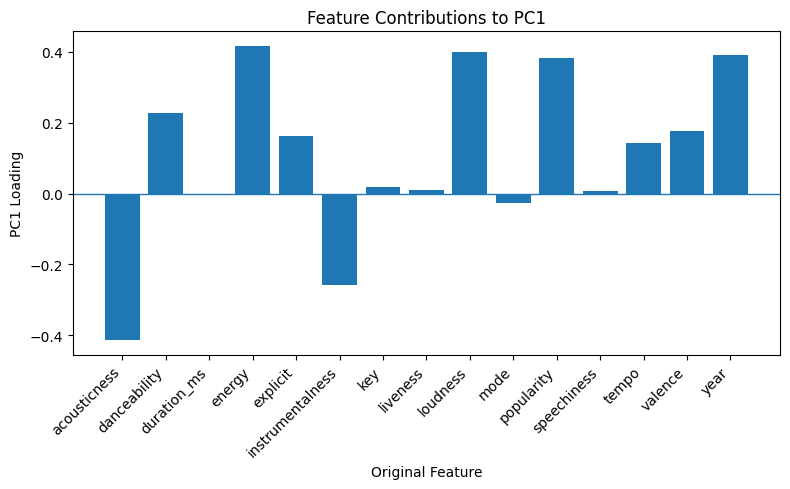

In [ ]:
# Loading Plot — “What does PC1 mean?”

pc1_loadings = pca.components_[0]

plt.figure(figsize=(8, 5))

plt.bar(numerical_features, pc1_loadings)

plt.axhline(0, linewidth=1)

plt.xlabel("Original Feature")
plt.ylabel("PC1 Loading")
plt.title("Feature Contributions to PC1")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

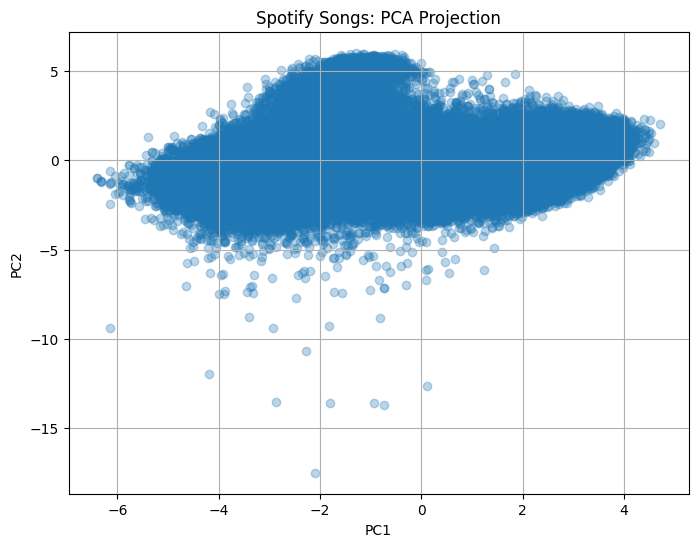

In [ ]:
# PC1 vs. PC2 Scatter Plot — “What does the reduced data look like?”

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.3
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Spotify Songs: PCA Projection")

plt.grid(True)
plt.show()

In [ ]:
print("Shape:", df.shape)
display(df.head())

# Basic information
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nData types:")
display(df.dtypes.value_counts())

# Inspect the columns
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Missing": df.isna().sum().values,
    "Missing %": (df.isna().mean() * 100).round(2).values,
    "Unique Values": df.nunique().values
}))

Shape: (169909, 19)


,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo,valence,year
0,0.995,['Carl Woitschach'],0.708,158648,0.1950,0,6KbQ3uYMLKb5jDxLF7wYDD,0.563,10,0.1510,-12.428,1,Singende Bataillone 1. Teil,0,1928,0.0506,118.469,0.7790,1928
1,0.994,"['Robert Schumann', 'Vladimir Horowitz']",0.379,282133,0.0135,0,6KuQTIu1KoTTkLXKrwlLPV,0.901,8,0.0763,-28.454,1,"Fantasiestücke, Op. 111: Più tosto lento",0,1928,0.0462,83.972,0.0767,1928
2,0.604,['Seweryn Goszczyński'],0.749,104300,0.2200,0,6L63VW0PibdM1HDSBoqnoM,0.000,5,0.1190,-19.924,0,Chapter 1.18 - Zamek kaniowski,0,1928,0.9290,107.177,0.8800,1928
3,0.995,['Francisco Canaro'],0.781,180760,0.1300,0,6M94FkXd15sOAOQYRnWPN8,0.887,1,0.1110,-14.734,0,Bebamos Juntos - Instrumental (Remasterizado),0,1928-09-25,0.0926,108.003,0.7200,1928
4,0.990,"['Frédéric Chopin', 'Vladimir Horowitz']",0.210,687733,0.2040,0,6N6tiFZ9vLTSOIxkj8qKrd,0.908,11,0.0980,-16.829,1,"Polonaise-Fantaisie in A-Flat Major, Op. 61",1,1928,0.0424,62.149,0.0693,1928


Number of rows: 169909
Number of columns: 19

Data types:


,count
float64,9
int64,6
object,4


,Column,Data Type,Missing,Missing %,Unique Values
acousticness,acousticness,float64,0,0.0,4714
artists,artists,object,0,0.0,33375
danceability,danceability,float64,0,0.0,1232
duration_ms,duration_ms,int64,0,0.0,50212
energy,energy,float64,0,0.0,2332
explicit,explicit,int64,0,0.0,2
id,id,object,0,0.0,169909
instrumentalness,instrumentalness,float64,0,0.0,5401
key,key,int64,0,0.0,12
liveness,liveness,float64,0,0.0,1741


In [ ]:
TARGET = "hit"    #"readmitted"
is_hit_threshold = 80
df[TARGET] = (df["popularity"] > is_hit_threshold).astype(int)
print("\nTarget distribution:")

display(df[TARGET].value_counts())

print("\nTarget proportion:")
display(df[TARGET].value_counts(normalize=True).rename("proportion"))


Target distribution:


,count
hit,
0,169452
1,457



Target proportion:


,proportion
hit,
0,0.99731
1,0.00269


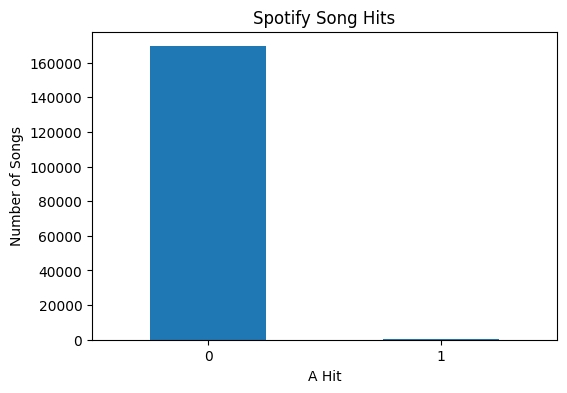

In [ ]:
#Visualize target imbalance
plt.figure(figsize=(6, 4))

df[TARGET].value_counts().plot(kind="bar")

plt.title("Spotify Song Hits")
plt.xlabel("A Hit")
plt.ylabel("Number of Songs")
plt.xticks(rotation=0)

plt.show()

In [ ]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical:")
print(numerical_features)

print("\nCategorical:")
print(categorical_features)

Numerical features: 15
Categorical features: 4

Numerical:
['acousticness', 'danceability', 'duration_ms', 'energy', 'explicit', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'popularity', 'speechiness', 'tempo', 'valence', 'year']

Categorical:
['artists', 'id', 'name', 'release_date']


In [ ]:
missing_count = df.isna().sum()

missing_count = (
    missing_count
    .sort_values(ascending=False)
)

display(missing_count.to_frame("Missing Count"))

,Missing Count
acousticness,0
artists,0
danceability,0
duration_ms,0
energy,0
explicit,0
id,0
instrumentalness,0
key,0
liveness,0


In [ ]:
numerical_features = [
    f for f in df.select_dtypes(include="number").columns
]
display(
    df[numerical_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
acousticness,169909.0,0.493214,0.376627,0.0,0.0945,0.492000,0.8880,0.996
danceability,169909.0,0.538150,0.175346,0.0,0.4170,0.548000,0.6670,0.988
duration_ms,169909.0,231406.158973,121321.923219,5108.0,171040.0000,208600.000000,262960.0000,5403500.000
energy,169909.0,0.488593,0.267390,0.0,0.2630,0.481000,0.7100,1.000
explicit,169909.0,0.084863,0.278679,0.0,0.0000,0.000000,0.0000,1.000
instrumentalness,169909.0,0.161937,0.309329,0.0,0.0000,0.000204,0.0868,1.000
key,169909.0,5.200519,3.515257,0.0,2.0000,5.000000,8.0000,11.000
liveness,169909.0,0.206690,0.176796,0.0,0.0984,0.135000,0.2630,1.000
loudness,169909.0,-11.370289,5.666765,-60.0,-14.4700,-10.474000,-7.1180,3.855
mode,169909.0,0.708556,0.454429,0.0,0.0000,1.000000,1.0000,1.000


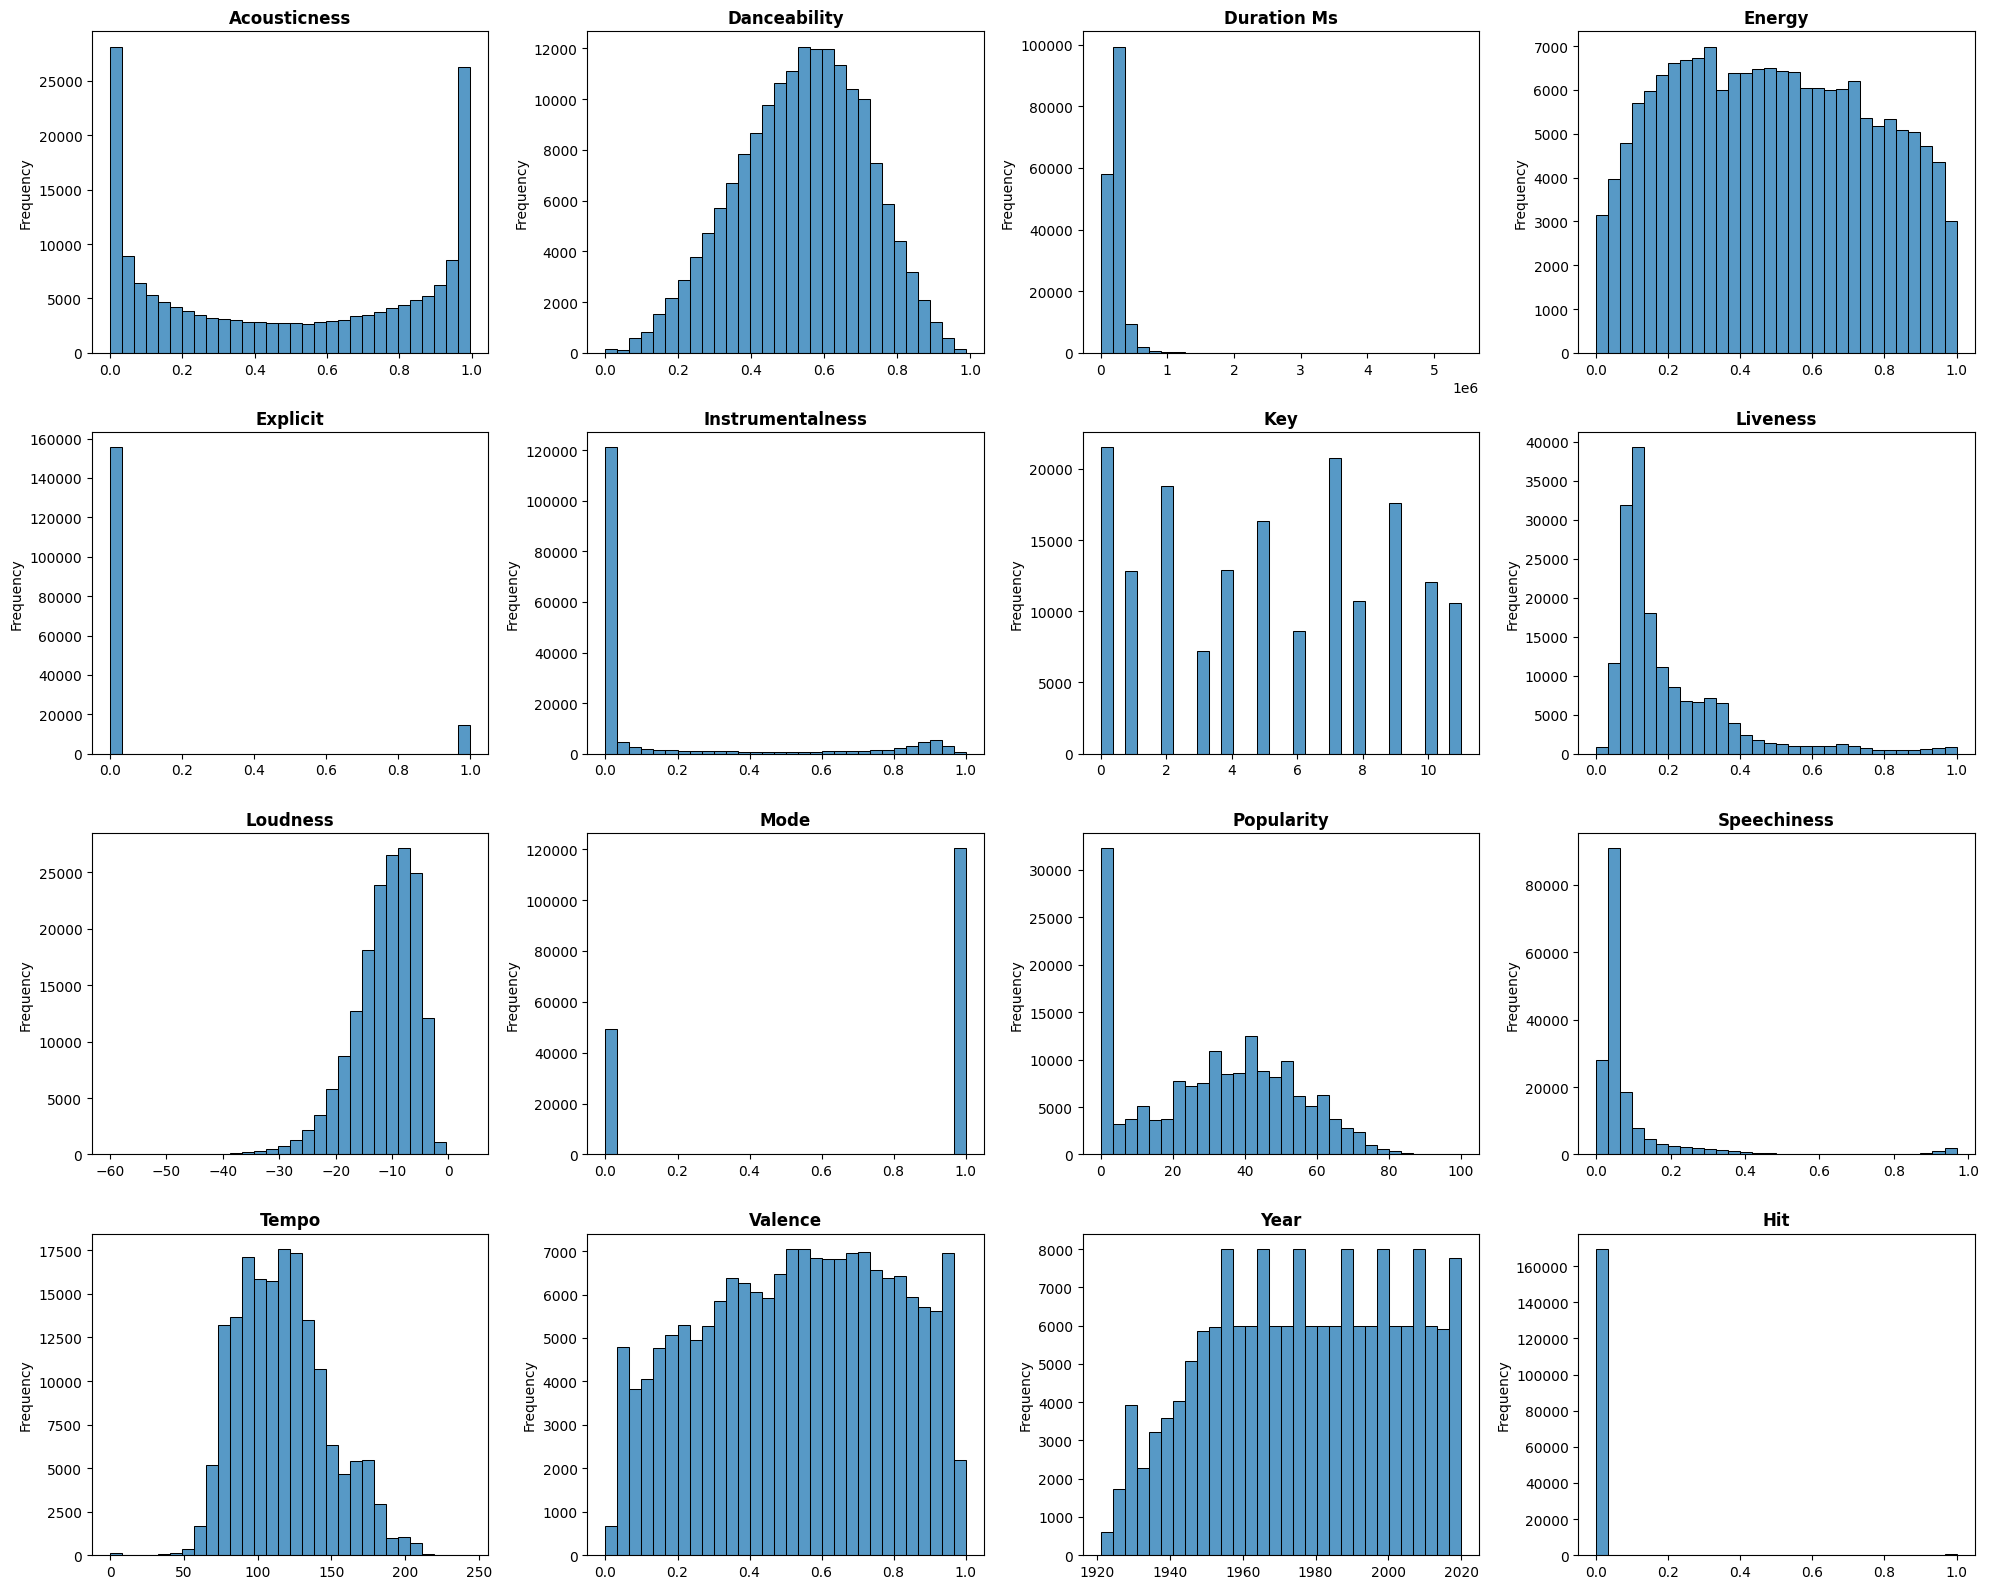

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Define numerical features
numerical_features = [
    f for f in df.select_dtypes(include="number").columns
]
# Set subplot layout
n_features = len(numerical_features)
n_cols = 4
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, 4 * n_rows)
)

# Flatten axes for easy iteration
axes = axes.flatten()
# Plot one histogram per numerical feature
for i, feature in enumerate(numerical_features):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        edgecolor="black",
        ax=axes[i]
    )

    axes[i].set_title(
        feature.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequency")

# Hide unused subplots
for i in range(n_features, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

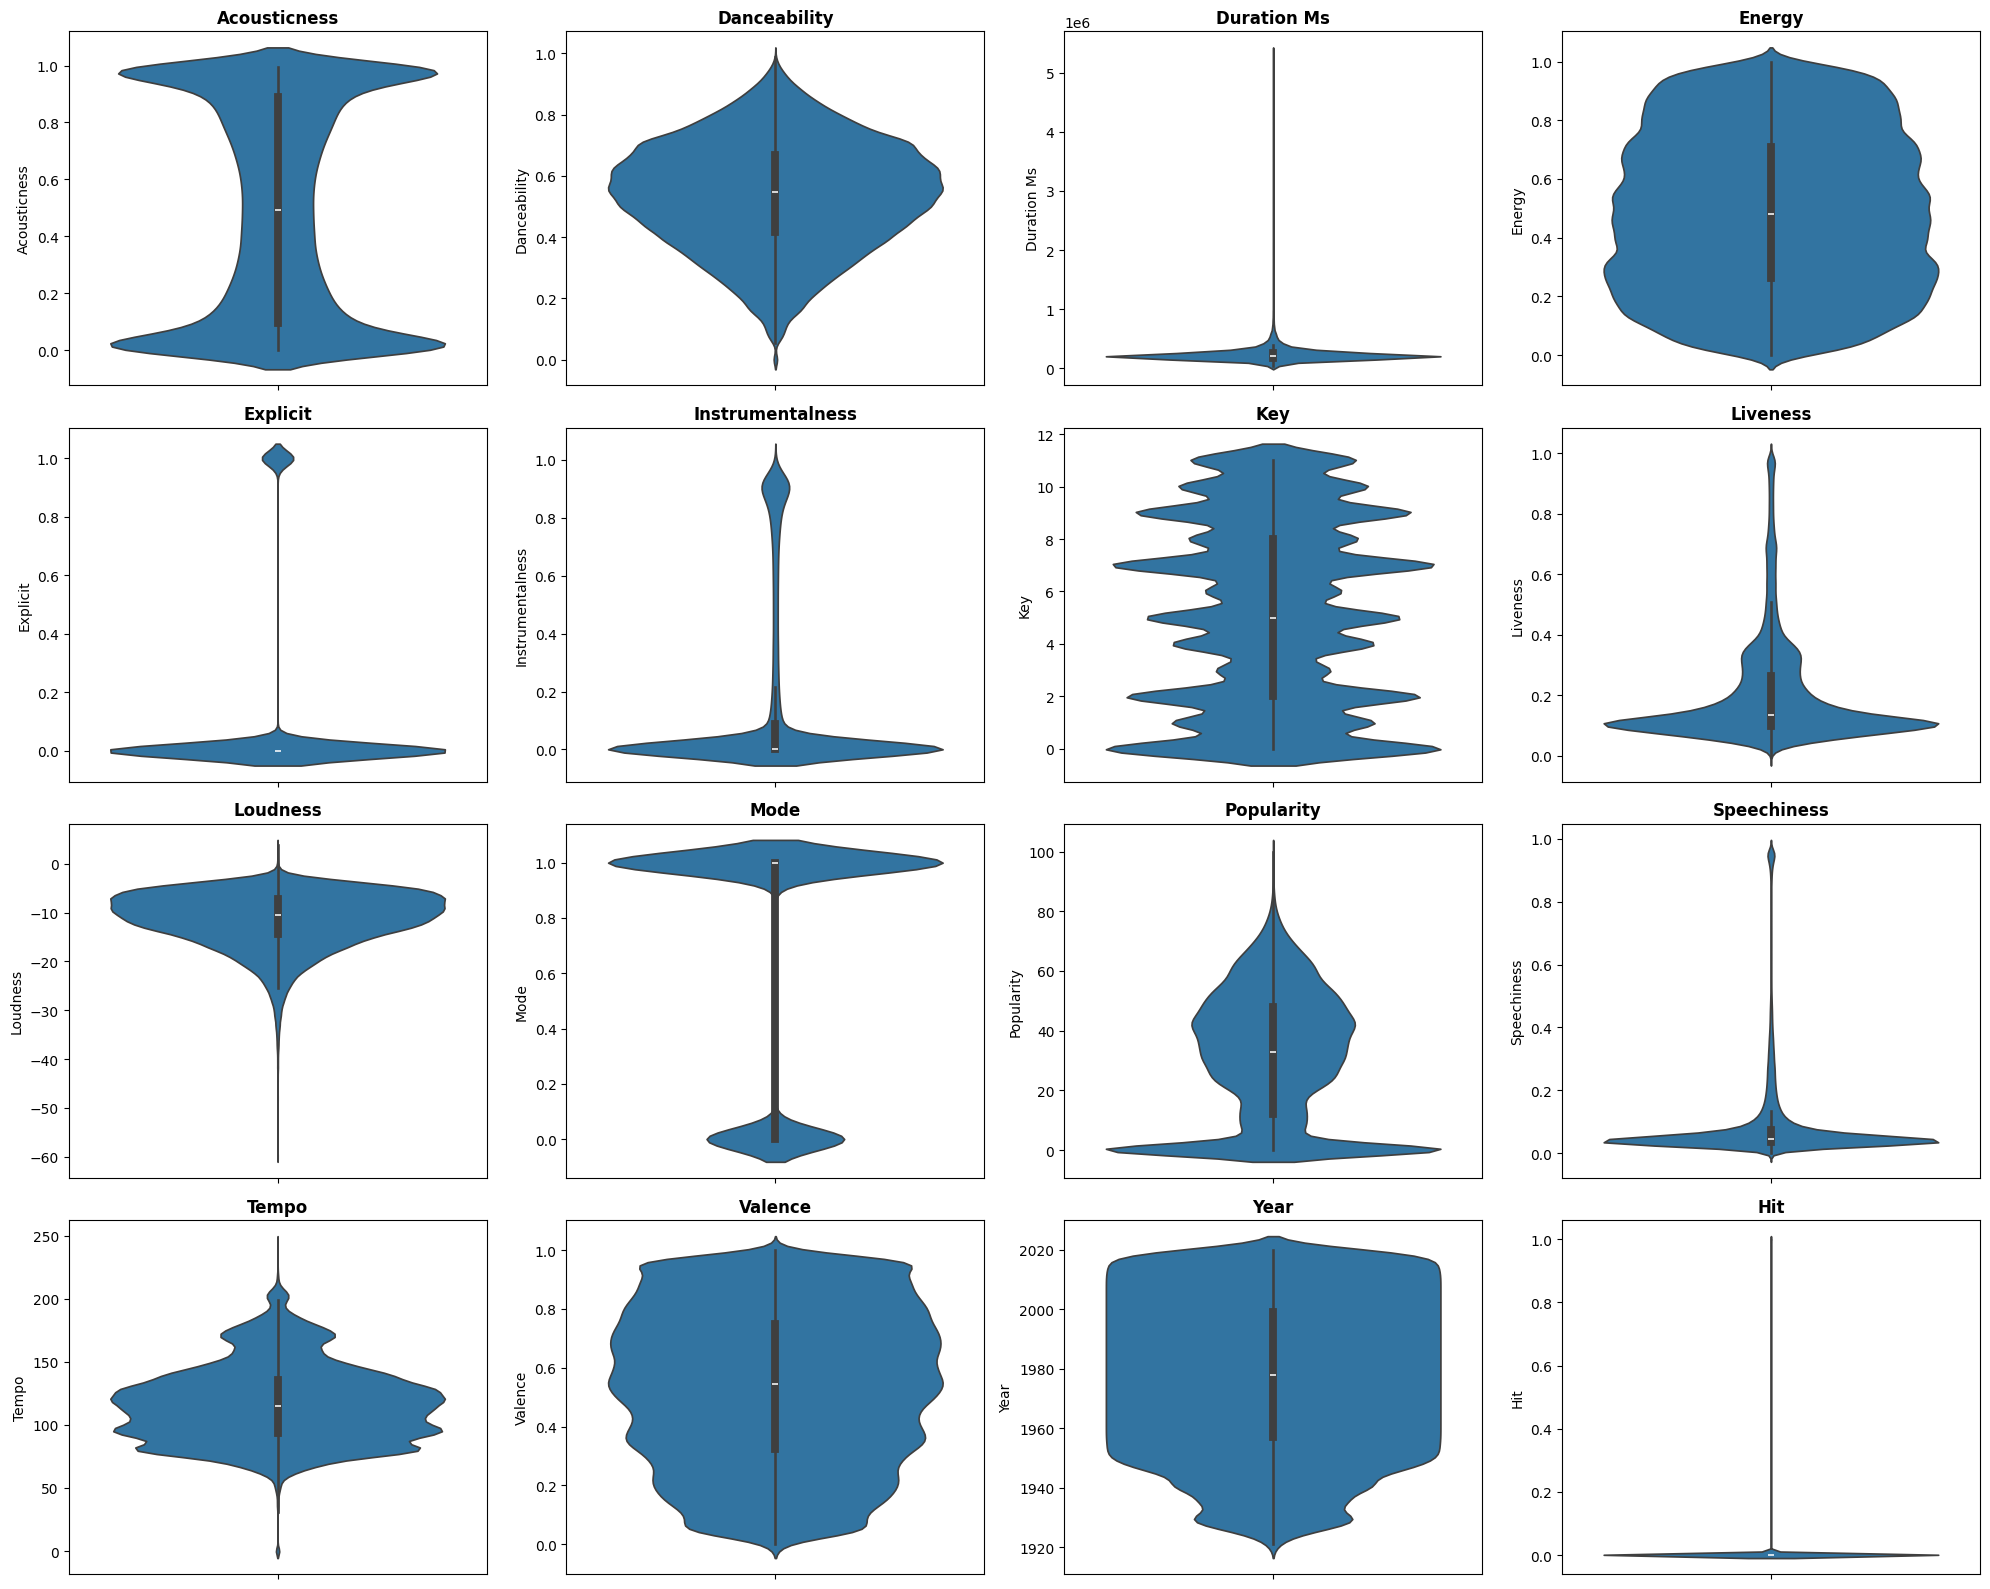

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Define numerical features
numerical_features = [
    f for f in df.select_dtypes(include="number").columns
]
# Set subplot layout
n_features = len(numerical_features)
n_cols = 4
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, 4 * n_rows)
)

# Flatten axes for easy iteration
axes = axes.flatten()

# Plot one violin plot per numerical feature
for i, feature in enumerate(numerical_features):
    sns.violinplot(
        data=df,
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(
        feature.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel(feature.replace("_", " ").title())

# Hide unused subplots
for i in range(n_features, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

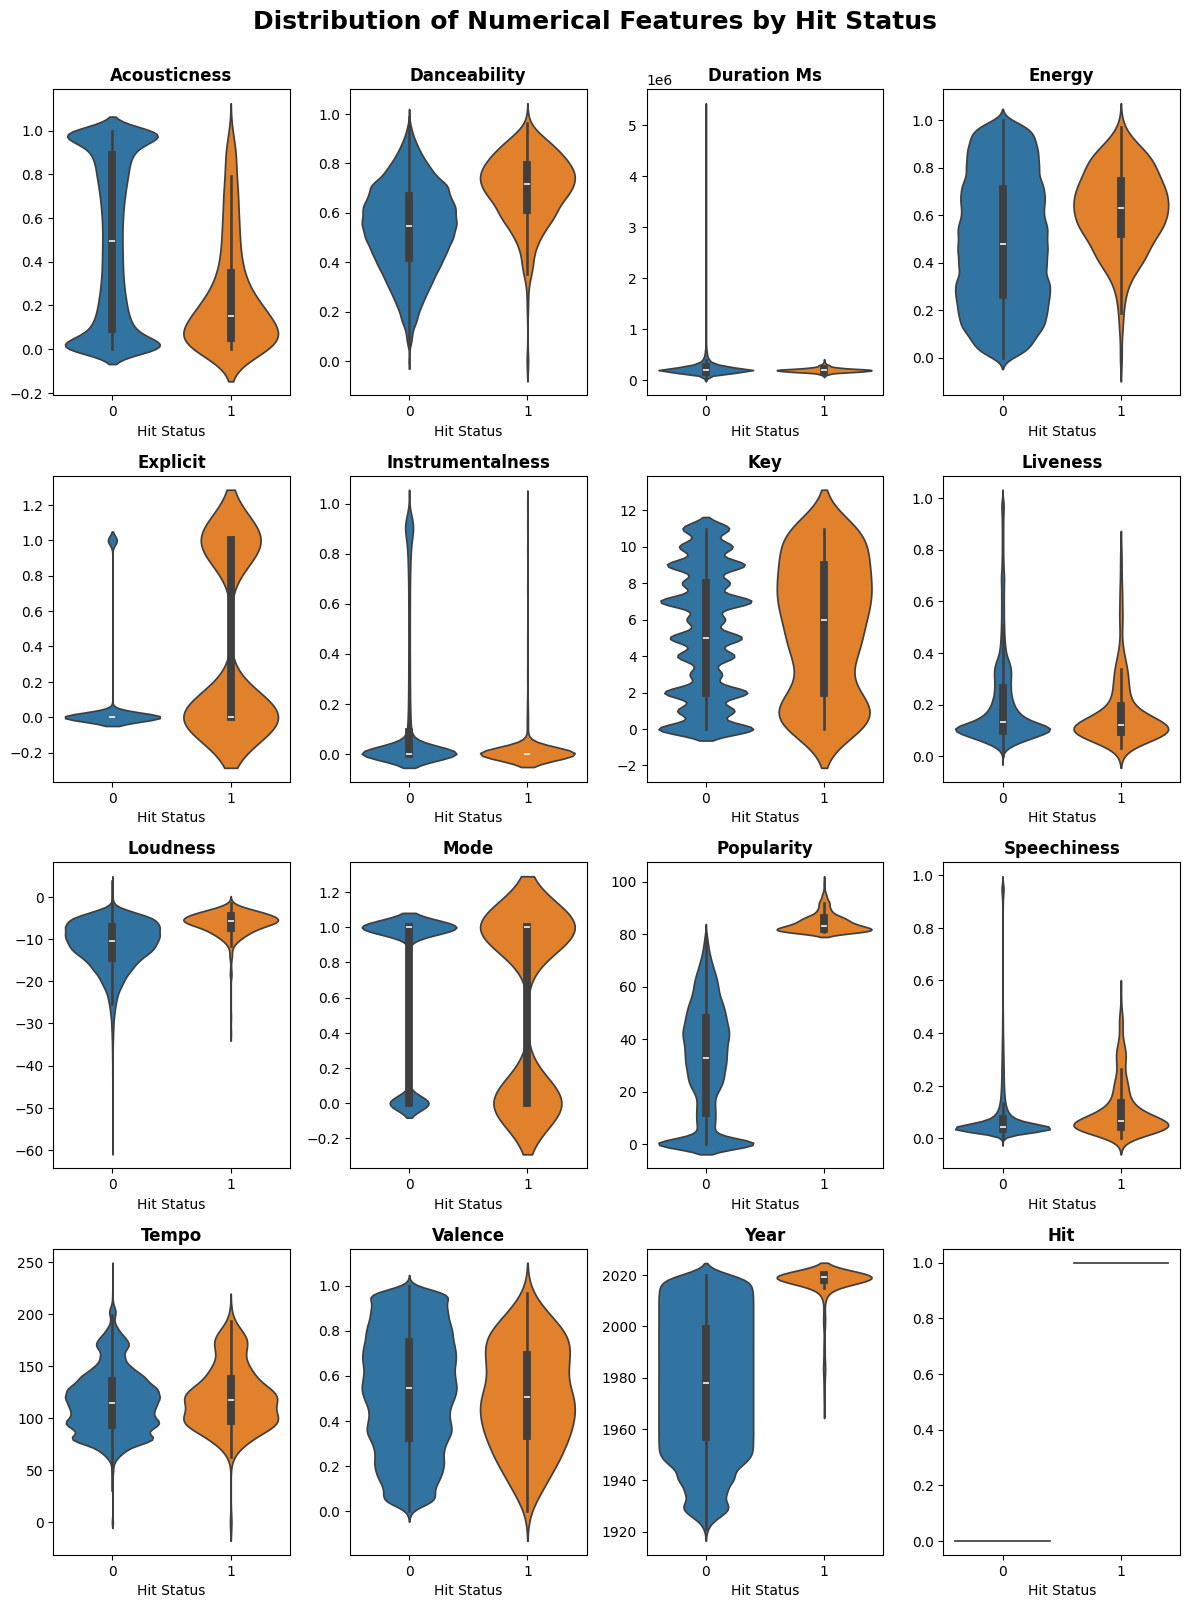

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Define numerical features
numerical_features = [
    f for f in df.select_dtypes(include="number").columns
]

# Subplot layout
n_features = len(numerical_features)
n_cols = 4
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 4 * n_rows)
)

# Flatten axes
axes = axes.flatten()

# Plot each numeric attribute
for i, feature in enumerate(numerical_features):

    sns.violinplot(
        data=df,
        x=TARGET,
        y=feature,
        hue=TARGET,
        inner="box",
        ax=axes[i],
        legend=False
    )

    axes[i].set_title(
        feature.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("Hit Status")
    axes[i].set_ylabel("")

# Hide unused subplots
for i in range(n_features, len(axes)):
    axes[i].set_visible(False)

fig.suptitle(
    "Distribution of Numerical Features by Hit Status",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.feature_selection import mutual_info_classif

X = df[numerical_features].drop(columns=["hit"])
y = df["hit"]

mi = mutual_info_classif(X, y, random_state=42)

mi_result = (
    pd.DataFrame({
        "feature": X.columns,
        "mutual_information": mi
    })
    .sort_values("mutual_information", ascending=False)
)

print(mi_result)

             feature  mutual_information
9               mode            0.036114
13              year            0.007095
6                key            0.003313
8           loudness            0.001866
4           explicit            0.001654
0       acousticness            0.001554
11             tempo            0.001544
1       danceability            0.001507
2        duration_ms            0.001173
3             energy            0.000927
5   instrumentalness            0.000898
10       speechiness            0.000560
12           valence            0.000252
7           liveness            0.000203


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

target = "hit"

numerical_features = [
    f for f in df.select_dtypes(include="number").columns
    if f not in ['hit', 'popularity']
]

X = df[numerical_features]
y = df[target]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for feature in numerical_features:

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ])

    # Out-of-fold predictions
    prob = cross_val_predict(
        model,
        X[[feature]],
        y,
        cv=cv,
        method="predict_proba"
    )[:, 1]

    roc = roc_auc_score(y, prob)
    pr = average_precision_score(y, prob)

    results.append({
        "feature": feature,
        "ROC_AUC": roc,
        "PR_AUC": pr
    })

# Convert the loop results into a DataFrame
results_df = pd.DataFrame(results)

# Compute correlation of each feature with target 'y'
correlations = X.corrwith(y).rename("correlation")

# Merge into your existing final matrix
final_matrix = (
    mi_result
    .merge(results_df, on="feature")
    .merge(correlations, left_on="feature", right_index=True)
)

# Reorder columns for optimal readability
final_matrix = final_matrix[["feature", "correlation", "mutual_information", "ROC_AUC", "PR_AUC"]]
final_matrix = final_matrix.sort_values("PR_AUC", ascending=False).reset_index(drop=True)

final_matrix

,feature,correlation,mutual_information,ROC_AUC,PR_AUC
0,year,0.079847,0.007095,0.954855,0.064774
1,loudness,0.046549,0.001866,0.805251,0.008133
2,danceability,0.046615,0.001507,0.763912,0.007854
3,explicit,0.056361,0.001654,0.637723,0.006395
4,instrumentalness,-0.024697,0.000898,0.672085,0.004310
5,speechiness,0.005316,0.000560,0.625458,0.003937
6,acousticness,-0.034552,0.001554,0.672732,0.003850
7,energy,0.026260,0.000927,0.652271,0.003569
8,mode,-0.014456,0.036114,0.556519,0.003232
9,key,0.005798,0.003313,0.525671,0.002998


In [ ]:
import pandas as pd

def analyze_feature_metrics(df):
    """
    Categorizes features into action groups based on correlation,
    mutual information, ROC_AUC, and PR_AUC thresholds.
    """
    actions = []

    for idx, row in df.iterrows():
        feat = row['feature']
        r = row['correlation']
        mi = row['mutual_information']
        roc = row['ROC_AUC']
        pr = row['PR_AUC']

        # 1. Primary Drivers (Keep as-is for base models)
        if pr > 0.01 or roc > 0.80 or abs(r) > 0.05:
            action = "KEEP (Primary Linear Signal)"
            rec = "Use as core features. Watch out for recency bias in 'year'."

        # 2. Strong Non-Linear Signals (Needs Binning / Target Encoding)
        elif mi > 0.003 and abs(r) < 0.02:
            action = "ENGINEER (Non-Linear Interaction)"
            rec = "Combine/bin feature (e.g., Target Encode 'key' or 'mode')."

        # 3. Weak Signal (Needs Feature Combination)
        elif roc > 0.60 or mi > 0.001:
            action = "TRANSFORM (Weak Secondary Signal)"
            rec = "Create interaction terms (e.g., energy/loudness, danceability*valence)."

        # 4. Pure Noise / Uninformative
        else:
            action = "DROP (Candidate for Removal)"
            rec = "Negligible signal across all 4 metrics. Drop to reduce noise."

        actions.append({
            "feature": feat,
            "Action_Category": action,
            "Recommendation": rec
        })

    action_df = pd.DataFrame(actions)
    return df.merge(action_df, on="feature")

# Process your dataframe
results_summary = analyze_feature_metrics(final_matrix)
print(results_summary[["feature", "Action_Category", "Recommendation"]])

             feature                    Action_Category  \
0               year       KEEP (Primary Linear Signal)   
1           loudness       KEEP (Primary Linear Signal)   
2       danceability  TRANSFORM (Weak Secondary Signal)   
3           explicit       KEEP (Primary Linear Signal)   
4   instrumentalness  TRANSFORM (Weak Secondary Signal)   
5        speechiness  TRANSFORM (Weak Secondary Signal)   
6       acousticness  TRANSFORM (Weak Secondary Signal)   
7             energy  TRANSFORM (Weak Secondary Signal)   
8               mode  ENGINEER (Non-Linear Interaction)   
9                key  ENGINEER (Non-Linear Interaction)   
10          liveness       DROP (Candidate for Removal)   
11             tempo  TRANSFORM (Weak Secondary Signal)   
12           valence       DROP (Candidate for Removal)   
13       duration_ms  TRANSFORM (Weak Secondary Signal)   

                                       Recommendation  
0   Use as core features. Watch out for recency bi...  
1 

In [ ]:
import numpy as np
import pandas as pd

def analyze_feature_metrics_general(df, y):
    """
    Dynamically categorizes features using dataset-relative baseline thresholds.
    """
    # Dynamic Baselines
    pos_rate = y.mean()  # Random baseline for PR_AUC
    pr_threshold = pos_rate * 2.0  # Feature provides >2x lift over baseline
    mi_median = df['mutual_information'].median()

    actions = []

    for idx, row in df.iterrows():
        feat = row['feature']
        r = row['correlation']
        mi = row['mutual_information']
        roc = row['ROC_AUC']
        pr = row['PR_AUC']

        # Relative Logic
        if pr > pr_threshold or roc > 0.70 or abs(r) > 0.20:
            action = "KEEP (Primary Signal)"
        elif mi > mi_median and abs(r) < 0.05:
            action = "ENGINEER (Non-Linear Interaction)"
        elif roc > 0.55 or mi > 0.0:
            action = "TRANSFORM (Weak Secondary Signal)"
        else:
            action = "DROP (Low Signal)"

        actions.append({"feature": feat, "Action_Category": action})

    return df.merge(pd.DataFrame(actions), on="feature")

results_summary = analyze_feature_metrics_general(final_matrix, y)
print(results_summary[["feature", "Action_Category"]])

             feature                    Action_Category
0               year              KEEP (Primary Signal)
1           loudness              KEEP (Primary Signal)
2       danceability              KEEP (Primary Signal)
3           explicit              KEEP (Primary Signal)
4   instrumentalness  TRANSFORM (Weak Secondary Signal)
5        speechiness  TRANSFORM (Weak Secondary Signal)
6       acousticness  ENGINEER (Non-Linear Interaction)
7             energy  TRANSFORM (Weak Secondary Signal)
8               mode  ENGINEER (Non-Linear Interaction)
9                key  ENGINEER (Non-Linear Interaction)
10          liveness  TRANSFORM (Weak Secondary Signal)
11             tempo  ENGINEER (Non-Linear Interaction)
12           valence  TRANSFORM (Weak Secondary Signal)
13       duration_ms  TRANSFORM (Weak Secondary Signal)


In [ ]:
!pip install pandas numpy scikit-learn category_encoders

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 3.4 MB/s eta 0:00:00


In [ ]:
pip install xgboost lightgbm

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score
import category_encoders as ce

def build_and_evaluate_pipeline(df, model, model_name="Model", target_col='hit', current_year=2026, target_threshold=80):
    """
    Executes Feature Engineering, Preprocessing, Model Training,
    and Evaluation for any passed scikit-learn compatible classifier.
    """
    # Create a copy to prevent modifying original dataframe
    data = df.copy()
    data[target_col] = (df['popularity'] > target_threshold).astype(int)
    ID_COLUMNS=["id"]
    categorical_features = [
        c for c in df.columns
        if c not in numerical_features
        and c not in ID_COLUMNS
    ]
    # ==========================================
    # 1. DROP UNINFORMATIVE FEATURES
    # ==========================================
    drop_cols = ['liveness', 'tempo', 'duration_ms', 'id', 'popularity']
    data = data.drop(columns=[c for c in drop_cols if c in data.columns])
    data = data.drop(columns=[c for c in categorical_features])
    # ==========================================
    # 2. FEATURE ENGINEERING
    # ==========================================
    if 'year' in data.columns:
        data['years_since_release'] = current_year - data['year']
        data = data.drop(columns=['year'])

    if 'key' in data.columns and 'mode' in data.columns:
        data['key_mode'] = data['key'].astype(str) + "_" + data['mode'].astype(str)
        data = data.drop(columns=['key', 'mode'])

    if 'danceability' in data.columns and 'valence' in data.columns:
        data['dance_valence_prod'] = data['danceability'] * data['valence']
        data = data.drop(columns=['valence'])

    if 'energy' in data.columns and 'loudness' in data.columns:
        data['energy_loudness_ratio'] = data['energy'] / (np.abs(data['loudness']) + 1e-5)

    if 'energy' in data.columns and 'acousticness' in data.columns:
        data['acoustic_energy_diff'] = data['energy'] - data['acousticness']

    # ==========================================
    # 3. TRAIN / TEST SPLIT (Stratified)
    # ==========================================
    X = data.drop(columns=[target_col])
    y = data[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # ==========================================
    # 4. CATEGORICAL ENCODING
    # ==========================================
    if 'key_mode' in X_train.columns:
        target_enc = ce.TargetEncoder(cols=['key_mode'], smoothing=10)
        X_train['key_mode'] = target_enc.fit_transform(X_train['key_mode'], y_train)
        X_test['key_mode'] = target_enc.transform(X_test['key_mode'])

    # ==========================================
    # 5. MODEL TRAINING
    # ==========================================
    model.fit(X_train, y_train)

    # ==========================================
    # 6. EVALUATION
    # ==========================================
    y_probs = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc_score = auc(recall, precision)
    roc_auc_score_val = roc_auc_score(y_test, y_probs)

    print(f"=== {model_name.upper()} EVALUATION METRICS ===")
    print(f"PR_AUC  (Primary Metric) : {pr_auc_score:.5f}")
    print(f"ROC_AUC (Secondary Metric): {roc_auc_score_val:.5f}\n")

    # Feature Importance or Coefficients Handling
    importances = None
    if hasattr(model, 'feature_importances_'):
        importances = pd.DataFrame({
            'Feature': X_train.columns,
            'Importance': model.feature_importances_
        }).sort_values('Importance', ascending=False).reset_index(drop=True)
    elif hasattr(model, 'coef_'):
        importances = pd.DataFrame({
            'Feature': X_train.columns,
            'Coefficient': model.coef_[0]
        }).sort_values('Coefficient', ascending=False).reset_index(drop=True)

    metrics = {
        'Model': model_name,
        'PR_AUC': pr_auc_score,
        'ROC_AUC': roc_auc_score_val
    }

    return model, metrics, importances

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score
import category_encoders as ce
import xgboost as xgb
import lightgbm as lgb
def build_and_evaluate_pipeline(df, model, model_name="Model", target_col='hit', current_year=2026, target_threshold=80):
    """
    Executes Feature Engineering, Preprocessing, Model Training,
    and Evaluation for any passed scikit-learn compatible classifier.
    """
    data = df.copy()

    # 1. Create Target Variable
    data[target_col] = (data['popularity'] > target_threshold).astype(int)

    # 2. Drop Text/Metadata and Target-Leakage Columns
    # (Explicitly keep key/mode and core audio features)
    metadata_cols = ['id', 'name', 'artists', 'release_date', 'popularity']
    data = data.drop(columns=[c for c in metadata_cols if c in data.columns])

    # 3. Drop uninformative features as determined by analysis
    drop_cols = ['liveness', 'tempo', 'duration_ms']
    data = data.drop(columns=[c for c in drop_cols if c in data.columns])

    # 4. Feature Engineering
    if 'year' in data.columns:
        data['years_since_release'] = current_year - data['year']
        data = data.drop(columns=['year'])

    # Create interaction BEFORE dropping key/mode
    if 'key' in data.columns and 'mode' in data.columns:
        data['key_mode'] = data['key'].astype(str) + "_" + data['mode'].astype(str)
        data = data.drop(columns=['key', 'mode'])

    if 'danceability' in data.columns and 'valence' in data.columns:
        data['dance_valence_prod'] = data['danceability'] * data['valence']
        data = data.drop(columns=['valence'])

    if 'energy' in data.columns and 'loudness' in data.columns:
        data['energy_loudness_ratio'] = data['energy'] / (np.abs(data['loudness']) + 1e-5)

    if 'energy' in data.columns and 'acousticness' in data.columns:
        data['acoustic_energy_diff'] = data['energy'] - data['acousticness']

    # 5. Train / Test Split
    X = data.drop(columns=[target_col])
    y = data[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # 6. Categorical Encoding (Target Encode key_mode)
    if 'key_mode' in X_train.columns:
        target_enc = ce.TargetEncoder(cols=['key_mode'], smoothing=10)
        X_train['key_mode'] = target_enc.fit_transform(X_train['key_mode'], y_train)
        X_test['key_mode'] = target_enc.transform(X_test['key_mode'])

    # 7. Feature Scaling (Only applied for linear models like Logistic Regression)
    if isinstance(model, LogisticRegression):
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

    # 8. Model Training
    model.fit(X_train, y_train)

    # 9. Evaluation
    y_probs = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc_score = auc(recall, precision)
    roc_auc_score_val = roc_auc_score(y_test, y_probs)

    print(f"=== {model_name.upper()} EVALUATION METRICS ===")
    print(f"PR_AUC  (Primary Metric) : {pr_auc_score:.5f}")
    print(f"ROC_AUC (Secondary Metric): {roc_auc_score_val:.5f}\n")

    # Feature Importance Handling
    importances = None
    cols = X.columns if hasattr(X, 'columns') else X_train.columns
    if hasattr(model, 'feature_importances_'):
        importances = pd.DataFrame({
            'Feature': cols,
            'Importance': model.feature_importances_
        }).sort_values('Importance', ascending=False).reset_index(drop=True)
    elif hasattr(model, 'coef_'):
        importances = pd.DataFrame({
            'Feature': cols,
            'Coefficient': model.coef_[0]
        }).sort_values('Coefficient', ascending=False).reset_index(drop=True)

    metrics = {
        'Model': model_name,
        'PR_AUC': pr_auc_score,
        'ROC_AUC': roc_auc_score_val
    }

    return model, metrics, importances

# Load Dataset and Execute Loop
url = "https://webpages.charlotte.edu/qcheng1/tbox/3162/data/songs-ori.csv"
df = pd.read_csv(url)
# Calculate ratio of negative to positive class for scale_pos_weight
neg_pos_ratio = (len(df) - (df['popularity'] > 80).sum()) / (df['popularity'] > 80).sum()
models_to_compare = {
    "XGBoost": xgb.XGBClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.05,
        scale_pos_weight=neg_pos_ratio, random_state=42, eval_metric='logloss'
    ),
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.05,
        scale_pos_weight=neg_pos_ratio, random_state=42, verbose=-1
    ),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=42),
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
}

comparison_results = []

for name, model_inst in models_to_compare.items():
    _, metrics, _ = build_and_evaluate_pipeline(df, model=model_inst, model_name=name, target_col='hit', target_threshold=80)
    comparison_results.append(metrics)

summary_df = pd.DataFrame(comparison_results).sort_values('PR_AUC', ascending=False)
print("=== FINAL MODEL COMPARISON SUMMARY ===")
print(summary_df.to_string(index=False))

=== XGBOOST EVALUATION METRICS ===
PR_AUC  (Primary Metric) : 0.11921
ROC_AUC (Secondary Metric): 0.95143

=== LIGHTGBM EVALUATION METRICS ===
PR_AUC  (Primary Metric) : 0.41500
ROC_AUC (Secondary Metric): 0.86640

=== RANDOM FOREST EVALUATION METRICS ===
PR_AUC  (Primary Metric) : 0.08871
ROC_AUC (Secondary Metric): 0.95144

=== DECISION TREE EVALUATION METRICS ===
PR_AUC  (Primary Metric) : 0.41635
ROC_AUC (Secondary Metric): 0.92996

=== LOGISTIC REGRESSION EVALUATION METRICS ===
PR_AUC  (Primary Metric) : 0.05771
ROC_AUC (Secondary Metric): 0.94921

=== FINAL MODEL COMPARISON SUMMARY ===
              Model   PR_AUC  ROC_AUC
      Decision Tree 0.416348 0.929956
           LightGBM 0.414997 0.866400
            XGBoost 0.119211 0.951431
      Random Forest 0.088709 0.951444
Logistic Regression 0.057712 0.949210


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score

def evaluate_baseline_logistic(df, target_threshold=80, target_col='hit'):
    """
    Trains a baseline Logistic Regression model using raw features.
    """
    data = df.copy()

    # 1. Create Target Variable
    data[target_col] = (data['popularity'] > target_threshold).astype(int)

    # 2. Drop non-numeric metadata and target leakage columns
    metadata_cols = ['id', 'name', 'artists', 'release_date', 'popularity']
    data = data.drop(columns=[c for c in metadata_cols if c in data.columns])

    # 3. Separate features and target
    X = data.drop(columns=[target_col])
    y = data[target_col]

    # Select only raw numeric features (skip string/object types if any remain)
    X = X.select_dtypes(include=[np.number])

    # 4. Train / Test Split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # 5. Build Baseline Pipeline (Impute Missing Values -> Scale -> Fit)
    baseline_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        #('scaler', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ])

    baseline_pipeline.fit(X_train, y_train)

    # 6. Evaluate Baseline
    y_probs = baseline_pipeline.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc_score = auc(recall, precision)
    roc_auc_score_val = roc_auc_score(y_test, y_probs)

    print("=== RAW DATA BASELINE: LOGISTIC REGRESSION ===")
    print(f"Features Used ({len(X.columns)}) : {list(X.columns)}")
    print(f"PR_AUC  (Primary Metric) : {pr_auc_score:.5f}")
    print(f"ROC_AUC (Secondary Metric): {roc_auc_score_val:.5f}\n")

    return baseline_pipeline, {"Model": "Baseline (Raw Logistic)", "PR_AUC": pr_auc_score, "ROC_AUC": roc_auc_score_val}

# Execute Baseline
url = "https://webpages.charlotte.edu/qcheng1/tbox/3162/data/songs-ori.csv"
df = pd.read_csv(url)

baseline_model, baseline_metrics = evaluate_baseline_logistic(df, target_threshold=80)

=== RAW DATA BASELINE: LOGISTIC REGRESSION ===
Features Used (14) : ['acousticness', 'danceability', 'duration_ms', 'energy', 'explicit', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'valence', 'year']
PR_AUC  (Primary Metric) : 0.01879
ROC_AUC (Secondary Metric): 0.88365



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_baseline_linear(df, target_col='popularity'):
    """
    Trains a baseline Linear Regression model using raw features to predict popularity.
    """
    data = df.copy()

    # 1. Target Variable is continuous popularity
    y = data[target_col]

    # 2. Drop non-numeric metadata and target column from X
    metadata_cols = ['id', 'name', 'artists', 'release_date', target_col]
    X = data.drop(columns=[c for c in metadata_cols if c in data.columns])

    # 3. Select only raw numeric features
    X = X.select_dtypes(include=[np.number])

    # 4. Train / Test Split (no stratification for continuous target)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # 5. Build Baseline Pipeline (Impute Missing Values -> Scale -> Fit)
    baseline_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', LinearRegression())
    ])

    baseline_pipeline.fit(X_train, y_train)

    # 6. Evaluate Baseline
    y_pred = baseline_pipeline.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print("=== RAW DATA BASELINE: LINEAR REGRESSION ===")
    print(f"Features Used ({len(X.columns)}) : {list(X.columns)}")
    print(f"RMSE (Primary Metric)     : {rmse:.5f}")
    print(f"MAE  (Secondary Metric)    : {mae:.5f}")
    print(f"R² Score                  : {r2:.5f}\n")

    return baseline_pipeline, {"Model": "Baseline (Raw Linear)", "RMSE": rmse, "MAE": mae, "R2": r2}

# Execute Baseline
url = "https://webpages.charlotte.edu/qcheng1/tbox/3162/data/songs-ori.csv"
df = pd.read_csv(url)

baseline_model, baseline_metrics = evaluate_baseline_linear(df)

=== RAW DATA BASELINE: LINEAR REGRESSION ===
Features Used (14) : ['acousticness', 'danceability', 'duration_ms', 'energy', 'explicit', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'valence', 'year']
RMSE (Primary Metric)     : 10.08912
MAE  (Secondary Metric)    : 7.70798
R² Score                  : 0.78200



In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_baseline_linear_hit(df, target_col='popularity', hit_threshold=80):
    """
    Trains a Linear Regression model to predict continuous popularity scores,
    classifies songs as 'hit' if score > hit_threshold, and evaluates ROC-AUC
    and associated classification and regression metrics.
    """
    data = df.copy()

    # 1. Target Variable is continuous popularity
    y = data[target_col]

    # 2. Drop non-numeric metadata and target column from X
    metadata_cols = ['id', 'name', 'artists', 'release_date', target_col]
    X = data.drop(columns=[c for c in metadata_cols if c in data.columns])

    # 3. Select only raw numeric features
    X = X.select_dtypes(include=[np.number])

    # 4. Train / Test Split (no stratification on continuous target)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # 5. Build Baseline Pipeline (Impute Missing Values -> Scale -> Fit)
    baseline_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', LinearRegression())
    ])

    baseline_pipeline.fit(X_train, y_train)

    # 6. Predict Continuous Popularity Scores
    y_pred = baseline_pipeline.predict(X_test)

    # 7. Define Binary 'Hit' Ground Truth and Binary Predictions (> hit_threshold)
    y_test_hit = (y_test > hit_threshold).astype(int)
    y_pred_hit = (y_pred > hit_threshold).astype(int)

    # 8. Regression Metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # 9. Binary Classification & ROC-AUC Metrics
    # Note: Raw predicted popularity scores are used as confidence scores for ROC-AUC
    if len(np.unique(y_test_hit)) > 1:
        roc_auc = roc_auc_score(y_test_hit, y_pred)
    else:
        roc_auc = np.nan

    acc = accuracy_score(y_test_hit, y_pred_hit)
    precision = precision_score(y_test_hit, y_pred_hit, zero_division=0)
    recall = recall_score(y_test_hit, y_pred_hit, zero_division=0)
    f1 = f1_score(y_test_hit, y_pred_hit, zero_division=0)
    cm = confusion_matrix(y_test_hit, y_pred_hit)

    # 10. Display Results
    print("=== RAW DATA BASELINE: LINEAR REGRESSION WITH HIT EVALUATION ===")
    print(f"Features Used ({len(X.columns)}) : {list(X.columns)}")
    print(f"Hit Condition            : Popularity > {hit_threshold}")
    print(f"Actual Hits in Test Set  : {y_test_hit.sum()} / {len(y_test_hit)} ({y_test_hit.mean()*100:.2f}%)\n")

    print("--- REGRESSION METRICS ---")
    print(f"RMSE                     : {rmse:.5f}")
    print(f"MAE                      : {mae:.5f}")
    print(f"R² Score                 : {r2:.5f}\n")

    print("--- CLASSIFICATION & ROC-AUC METRICS ---")
    if not np.isnan(roc_auc):
        print(f"ROC-AUC Score            : {roc_auc:.5f}")
    else:
        print("ROC-AUC Score            : N/A (Only one class present in test set)")
    print(f"Accuracy                 : {acc:.5f}")
    print(f"Precision                : {precision:.5f}")
    print(f"Recall                   : {recall:.5f}")
    print(f"F1-Score                 : {f1:.5f}\n")

    print("--- CONFUSION MATRIX ---")
    print(cm)
    print("\n--- CLASSIFICATION REPORT ---")
    print(classification_report(y_test_hit, y_pred_hit, target_names=['Non-Hit', 'Hit'], zero_division=0))

    metrics = {
        "Model": "Baseline (Linear Reg + Hit Threshold)",
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "ROC_AUC": roc_auc,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }

    return baseline_pipeline, metrics

# Execute Baseline
url = "https://webpages.charlotte.edu/qcheng1/tbox/3162/data/songs-ori.csv"
df = pd.read_csv(url)

baseline_model, baseline_metrics = evaluate_baseline_linear_hit(df, hit_threshold=80)


=== RAW DATA BASELINE: LINEAR REGRESSION WITH HIT EVALUATION ===
Features Used (14) : ['acousticness', 'danceability', 'duration_ms', 'energy', 'explicit', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'valence', 'year']
Hit Condition            : Popularity > 80
Actual Hits in Test Set  : 96 / 33982 (0.28%)

--- REGRESSION METRICS ---
RMSE                     : 10.08912
MAE                      : 7.70798
R² Score                 : 0.78200

--- CLASSIFICATION & ROC-AUC METRICS ---
ROC-AUC Score            : 0.94737
Accuracy                 : 0.99717
Precision                : 0.00000
Recall                   : 0.00000
F1-Score                 : 0.00000

--- CONFUSION MATRIX ---
[[33886     0]
 [   96     0]]

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Non-Hit       1.00      1.00      1.00     33886
         Hit       0.00      0.00      0.00        96

    accuracy                           1.00     33

In [ ]:
# Add baseline metrics to your previous results array
comparison_results.append(baseline_metrics)

# Display final comparison table
summary_df = pd.DataFrame(comparison_results).sort_values('PR_AUC', ascending=False)
print("=== FINAL MODEL COMPARISON SUMMARY ===")
print(summary_df.to_string(index=False))

=== FINAL MODEL COMPARISON SUMMARY ===
                  Model   PR_AUC  ROC_AUC
          Decision Tree 0.416348 0.929956
          Random Forest 0.088709 0.951444
Baseline (Raw Logistic) 0.058179 0.948797
    Logistic Regression 0.057712 0.949210


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score
import category_encoders as ce

# Gradient Boosting Frameworks
import xgboost as xgb
import lightgbm as lgb

# ==========================================
# 1. ENGINEERED PIPELINE FUNCTION
# ==========================================
def build_and_evaluate_pipeline(df, model, model_name="Model", target_col='hit', current_year=2026, target_threshold=80):
    data = df.copy()

    # Target Variable
    data[target_col] = (data['popularity'] > target_threshold).astype(int)

    # Drop Text/Metadata and Target-Leakage
    metadata_cols = ['id', 'name', 'artists', 'release_date', 'popularity']
    data = data.drop(columns=[c for c in metadata_cols if c in data.columns])

    # Drop uninformative features
    drop_cols = ['liveness', 'tempo', 'duration_ms']
    data = data.drop(columns=[c for c in drop_cols if c in data.columns])

    # Feature Engineering
    if 'year' in data.columns:
        data['years_since_release'] = current_year - data['year']
        data = data.drop(columns=['year'])

    if 'key' in data.columns and 'mode' in data.columns:
        data['key_mode'] = data['key'].astype(str) + "_" + data['mode'].astype(str)
        data = data.drop(columns=['key', 'mode'])

    if 'danceability' in data.columns and 'valence' in data.columns:
        data['dance_valence_prod'] = data['danceability'] * data['valence']
        data = data.drop(columns=['valence'])

    if 'energy' in data.columns and 'loudness' in data.columns:
        data['energy_loudness_ratio'] = data['energy'] / (np.abs(data['loudness']) + 1e-5)

    if 'energy' in data.columns and 'acousticness' in data.columns:
        data['acoustic_energy_diff'] = data['energy'] - data['acousticness']

    # Train / Test Split
    X = data.drop(columns=[target_col])
    y = data[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Categorical Target Encoding
    if 'key_mode' in X_train.columns:
        target_enc = ce.TargetEncoder(cols=['key_mode'], smoothing=10)
        X_train['key_mode'] = target_enc.fit_transform(X_train['key_mode'], y_train)
        X_test['key_mode'] = target_enc.transform(X_test['key_mode'])

    # Feature Scaling for Linear Models
    if isinstance(model, LogisticRegression):
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

    # Fit & Predict
    model.fit(X_train, y_train)
    y_probs = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc_score = auc(recall, precision)
    roc_auc_score_val = roc_auc_score(y_test, y_probs)

    metrics = {
        'Model': f"{model_name} (Engineered)",
        'PR_AUC': pr_auc_score,
        'ROC_AUC': roc_auc_score_val
    }

    return metrics

# ==========================================
# 2. RAW BASELINE FUNCTION
# ==========================================
def evaluate_baseline_logistic(df, target_threshold=80, target_col='hit'):
    data = df.copy()
    data[target_col] = (data['popularity'] > target_threshold).astype(int)

    metadata_cols = ['id', 'name', 'artists', 'release_date', 'popularity']
    data = data.drop(columns=[c for c in metadata_cols if c in data.columns])

    X = data.drop(columns=[target_col]).select_dtypes(include=[np.number])
    y = data[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    baseline_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ])

    baseline_pipeline.fit(X_train, y_train)
    y_probs = baseline_pipeline.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc_score = auc(recall, precision)
    roc_auc_score_val = roc_auc_score(y_test, y_probs)

    return {
        'Model': 'Baseline (Raw Logistic)',
        'PR_AUC': pr_auc_score,
        'ROC_AUC': roc_auc_score_val
    }

# ==========================================
# 3. EXECUTION & COMPARISON
# ==========================================
url = "https://webpages.charlotte.edu/qcheng1/tbox/3162/data/songs-ori.csv"
df = pd.read_csv(url)

comparison_results = []

# Run baseline
baseline_metrics = evaluate_baseline_logistic(df, target_threshold=80)
comparison_results.append(baseline_metrics)

# Calculate ratio of negative to positive class for scale_pos_weight
neg_pos_ratio = (len(df) - (df['popularity'] > 80).sum()) / (df['popularity'] > 80).sum()

# Define model suite including Gradient Boosted Trees
models_to_compare = {
    "XGBoost": xgb.XGBClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.05,
        scale_pos_weight=neg_pos_ratio, random_state=42, eval_metric='logloss'
    ),
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.05,
        scale_pos_weight=neg_pos_ratio, random_state=42, verbose=-1
    ),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=42),
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
}

for name, model_inst in models_to_compare.items():
    metrics = build_and_evaluate_pipeline(df, model=model_inst, model_name=name, target_col='hit', target_threshold=80)
    comparison_results.append(metrics)

# Display expanded summary table
summary_df = pd.DataFrame(comparison_results).sort_values('PR_AUC', ascending=False).reset_index(drop=True)
print("=== EXPANDED MODEL COMPARISON SUMMARY ===")
print(summary_df.to_string(index=False))

In [ ]:
ID_COLUMNS=["id"]
categorical_features = [
    c for c in df.columns
    if c not in numerical_features
    and c not in ID_COLUMNS
]

category_counts = pd.DataFrame({
    "Feature": categorical_features,
    "Number of Categories": [
        df[col].nunique(dropna=False)
        for col in categorical_features
    ]
})

display(
    category_counts
    .sort_values(
        "Number of Categories",
        ascending=False
    )
)

,Feature,Number of Categories
1,name,132940
0,artists,33375
2,release_date,10882


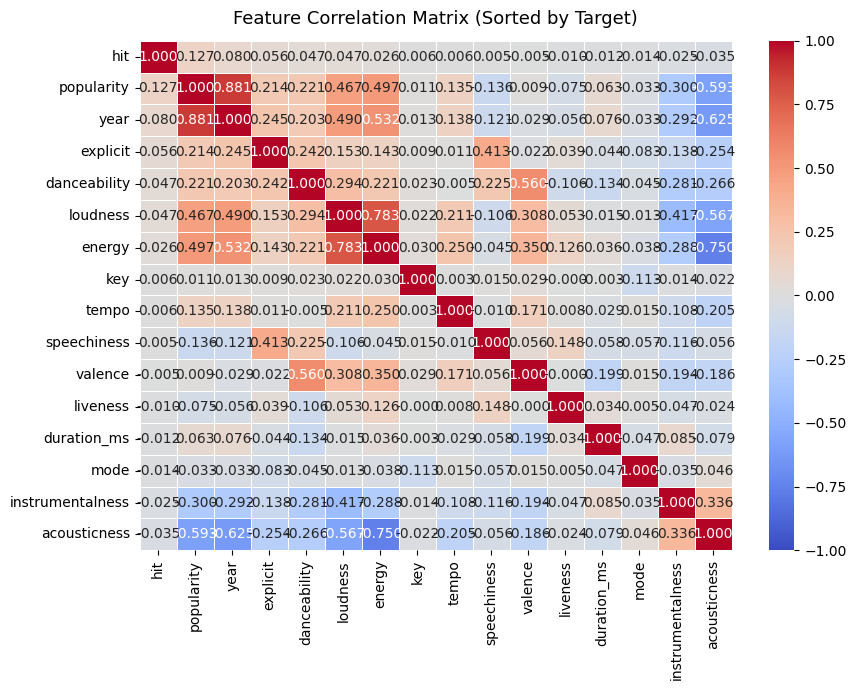

In [ ]:
raw_corr = df.corr(numeric_only=True)
sorted_cols = raw_corr[TARGET].sort_values(ascending=False).index
sorted_corr = raw_corr.loc[sorted_cols, sorted_cols]
#print("Raw Correlations:")
#print(sorted_corr)

plt.figure(figsize=(9, 7))
sns.heatmap(sorted_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".3f", linewidths=0.5)
plt.title("Feature Correlation Matrix (Sorted by Target)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

In [ ]:
corr_pairs = (
    sorted_corr
    .where(
        np.triu(
            np.ones(sorted_corr.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

corr_pairs["Absolute Correlation"] = (
    corr_pairs["Correlation"].abs()
)

high_corr_pairs = (
    corr_pairs
    .sort_values(
        "Absolute Correlation",
        ascending=False
    )
)

HIGH_CORRELATION_THRESHOLD = 0.2
display( high_corr_pairs[ high_corr_pairs["Absolute Correlation"] >= HIGH_CORRELATION_THRESHOLD ] )

,Feature 1,Feature 2,Correlation,Absolute Correlation
15,popularity,year,0.880724,0.880724
65,loudness,energy,0.782982,0.782982
83,energy,acousticness,-0.750283,0.750283
41,year,acousticness,-0.624550,0.624550
28,popularity,acousticness,-0.593345,0.593345
74,loudness,acousticness,-0.567072,0.567072
59,danceability,valence,0.560242,0.560242
32,year,energy,0.532419,0.532419
19,popularity,energy,0.497488,0.497488
31,year,loudness,0.490118,0.490118


In [ ]:
# 15.1 One-feature logistic regression
results = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for feature in numerical_features:

    X_feature = df[[feature]]

    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        LogisticRegression(
            max_iter=1000
        )
    )

    scores = cross_val_score(
        pipeline,
        X_feature,
        df[TARGET],
        cv=cv,
        scoring="roc_auc"
    )

    results.append({
        "Feature": feature,
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

univariate_results = (
    pd.DataFrame(results)
    .sort_values(
        "Mean ROC-AUC",
        ascending=False
    )
)

display(univariate_results)

,Feature,Mean ROC-AUC,Std ROC-AUC
15,hit,1.000000,0.000000
10,popularity,1.000000,0.000000
8,loudness,0.805424,0.014926
1,danceability,0.764049,0.010449
5,instrumentalness,0.705789,0.027937
0,acousticness,0.672498,0.024050
3,energy,0.652642,0.019407
4,explicit,0.651514,0.025991
9,mode,0.563419,0.013082
2,duration_ms,0.552788,0.022165


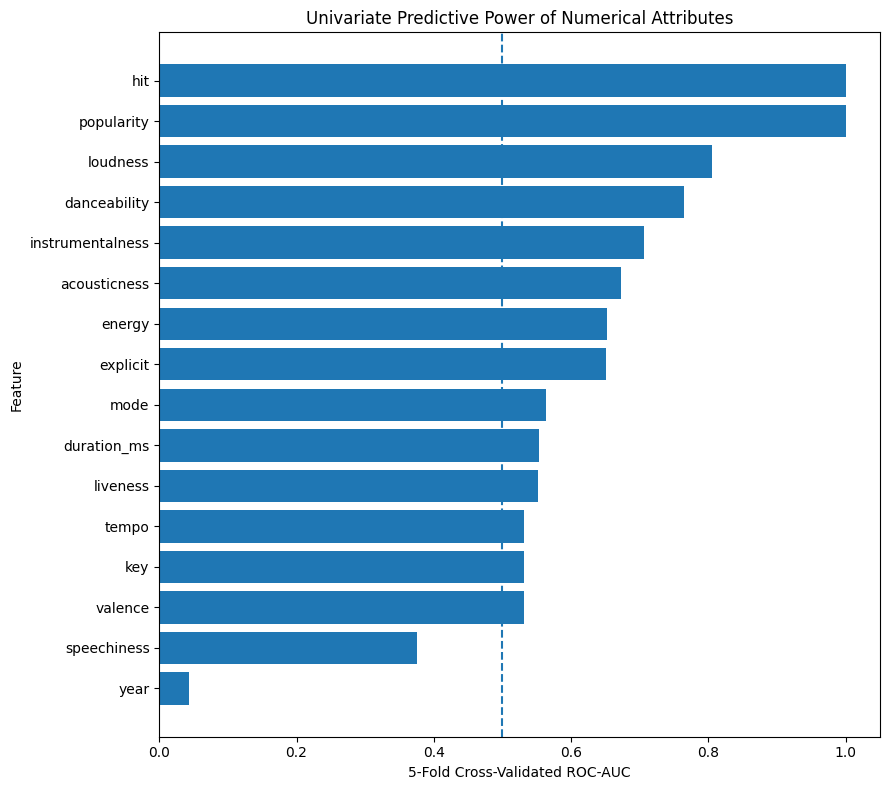

In [ ]:
plot_df = (
    univariate_results
    .sort_values("Mean ROC-AUC")
)

plt.figure(figsize=(9, 8))

plt.barh(
    plot_df["Feature"],
    plot_df["Mean ROC-AUC"]
)

plt.axvline(
    0.5,
    linestyle="--"
)

plt.xlabel("5-Fold Cross-Validated ROC-AUC")
plt.ylabel("Feature")
plt.title(
    "Univariate Predictive Power of Numerical Attributes"
)

plt.tight_layout()
plt.show()

1. Identify missing values
# Number of missing values in each column
df.isna().sum()

Missing-value percentage:

missing_pct = df.isna().mean() * 100
print(missing_pct.sort_values(ascending=False))
2. Remove rows with missing values
df_clean = df.dropna()

Or only remove rows missing a particular attribute:

df_clean = df.dropna(subset=["tempo"])
3. Fill missing values

Mean — appropriate for relatively symmetric numerical data:

df["tempo"] = df["tempo"].fillna(df["tempo"].mean())

Median — often better when the distribution is skewed or contains outliers:

df["duration_ms"] = df["duration_ms"].fillna(
    df["duration_ms"].median()
)

Mode — useful for categorical variables:

df["artist_name"] = df["artist_name"].fillna(
    df["artist_name"].mode()[0]
)
4. Treat missing values as a separate category

For categorical attributes:

df["artist_name"] = df["artist_name"].fillna("Unknown")

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# --------------------------------------------------
# Load data
# --------------------------------------------------
#df = pd.read_csv("dataset_for_students.csv")
url = "https://webpages.charlotte.edu/qcheng1/tbox/3162/data/songs-ori.csv"
df = pd.read_csv(url)

df = df[df["tempo"] > 0].copy()
df = df[df["duration_ms"] > 100000].copy()

target = "popularity"   #"readmitted"

# Convert target to binary
y = (df[target] > 80).astype(int)

X = df.drop(columns=[target])

# Remove identifiers that should not be predictive features
drop_cols = [
    "id",
    "name",
]
df = df.drop(columns=[c for c in drop_cols if c in X.columns])

# --------------------------------------------------
# Identify feature types
# --------------------------------------------------
numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()


# --------------------------------------------------
# Calculate univariate predictive power
# --------------------------------------------------
results = []

for feature in X.columns:

    if feature in numeric_features:

        preprocessor = Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ])

    else:

        preprocessor = Pipeline([
            ("imputer", SimpleImputer(
                strategy="most_frequent"
            )),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ])

    model = Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ])

    # Use a single feature
    X_feature = X[[feature]]

    X_train, X_test, y_train, y_test = train_test_split(
        X_feature,
        y,
        test_size=0.20,
        stratify=y,
        random_state=42
    )

    model.fit(X_train, y_train)

    probability = model.predict_proba(X_test)[:, 1]

    roc_auc = roc_auc_score(y_test, probability)
    pr_auc = average_precision_score(y_test, probability)

    # AUC is symmetric; make it >= 0.5
    roc_auc_strength = max(roc_auc, 1 - roc_auc)

    results.append({
        "feature": feature,
        "ROC_AUC": roc_auc,
        "AUC_strength": roc_auc_strength,
        "PR_AUC": pr_auc
    })


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "ROC_AUC",
    ascending=False
)

results_df.head(30)

,feature,ROC_AUC,AUC_strength,PR_AUC
17,year,0.954735,0.954735,0.053720
13,release_date,0.888096,0.888096,0.047635
1,artists,0.816013,0.816013,0.061413
10,loudness,0.804793,0.804793,0.008206
2,danceability,0.770044,0.770044,0.007923
7,instrumentalness,0.731036,0.731036,0.005734
5,explicit,0.672824,0.672824,0.007667
0,acousticness,0.663501,0.663501,0.003898
4,energy,0.639491,0.639491,0.003565
14,speechiness,0.631651,0.631651,0.004573


In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

X_mi = X.copy()

# Encode categorical variables
for col in X_mi.select_dtypes(
    include=["object", "category", "String"]
).columns:

    X_mi[col] = (
        X_mi[col]
        .astype("category")
        .cat.codes
    )

# Replace missing values
X_mi = X_mi.replace([-1], np.nan)

X_mi = X_mi.fillna(X_mi.median())

mi = mutual_info_classif(
    X_mi,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "feature": X_mi.columns,
    "mutual_information": mi
}).sort_values(
    "mutual_information",
    ascending=False
)

mi_df.head(30)

,feature,mutual_information
11,mode,0.033781
13,release_date,0.007408
17,year,0.007326
1,artists,0.005098
8,key,0.002877
10,loudness,0.001892
15,tempo,0.001629
5,explicit,0.001619
0,acousticness,0.001591
2,danceability,0.001529


In [ ]:
feature_power = results_df.merge(
    mi_df,
    on="feature",
    how="left"
)

feature_power = feature_power.sort_values(
    "PR_AUC",
    ascending=False
)

feature_power.head(30)

,feature,ROC_AUC,AUC_strength,PR_AUC,mutual_information
2,artists,0.816013,0.816013,0.061413,0.005098
0,year,0.954735,0.954735,0.053720,0.007326
1,release_date,0.888096,0.888096,0.047635,0.007408
16,name,0.512428,0.512428,0.012751,0.000997
3,loudness,0.804793,0.804793,0.008206,0.001892
4,danceability,0.770044,0.770044,0.007923,0.001529
6,explicit,0.672824,0.672824,0.007667,0.001619
5,instrumentalness,0.731036,0.731036,0.005734,0.000915
9,speechiness,0.631651,0.631651,0.004573,0.000627
7,acousticness,0.663501,0.663501,0.003898,0.001591


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score, classification_report
import category_encoders as ce

def build_and_evaluate_pipeline(df, target_col='hit', current_year=2026):
    """
    Executes Feature Engineering, Preprocessing, and Decision Tree Training
    based on the Feature Decision Matrix.
    """
    # Create a copy to prevent modifying original dataframe
    data = df.copy()

    # ==========================================
    # 1. DROP UNINFORMATIVE FEATURES
    # Strategy: Drop liveness, tempo, valence, duration_ms
    # ==========================================
    drop_cols = ['liveness', 'tempo', 'duration_ms']
    # Note: 'valence' is temporarily kept for an interaction feature, then dropped.
    data = data.drop(columns=[c for c in drop_cols if c in data.columns])

    # ==========================================
    # 2. FEATURE ENGINEERING
    # ==========================================

    # [YEAR]: Convert raw year to years_since_release to avoid recency leakage
    if 'year' in data.columns:
        data['years_since_release'] = current_year - data['year']
        data = data.drop(columns=['year'])

    # [MODE & KEY]: Combine into non-linear categorical interaction term 'key_mode'
    if 'key' in data.columns and 'mode' in data.columns:
        data['key_mode'] = data['key'].astype(str) + "_" + data['mode'].astype(str)
        data = data.drop(columns=['key', 'mode'])

    # [DANCEABILITY & VALENCE]: Create "upbeat danceability" interaction
    if 'danceability' in data.columns and 'valence' in data.columns:
        data['dance_valence_prod'] = data['danceability'] * data['valence']
        data = data.drop(columns=['valence']) # Drop standalone valence as planned

    # [ENERGY & LOUDNESS / ACOUSTICNESS]: Create domain interaction ratios/differences
    if 'energy' in data.columns and 'loudness' in data.columns:
        # Adding small constant to prevent division by zero
        data['energy_loudness_ratio'] = data['energy'] / (np.abs(data['loudness']) + 1e-5)

    if 'energy' in data.columns and 'acousticness' in data.columns:
        data['acoustic_energy_diff'] = data['energy'] - data['acousticness']

    # ==========================================
    # 3. TRAIN / TEST SPLIT (Stratified)
    # ==========================================
    X = data.drop(columns=[target_col])
    y = data[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # ==========================================
    # 4. CATEGORICAL ENCODING
    # Strategy: Target Encode 'key_mode' using Out-of-Fold logic to prevent leakage
    # ==========================================
    if 'key_mode' in X_train.columns:
        target_enc = ce.TargetEncoder(cols=['key_mode'], smoothing=10)
        X_train['key_mode'] = target_enc.fit_transform(X_train['key_mode'], y_train)
        X_test['key_mode'] = target_enc.transform(X_test['key_mode'])

    # ==========================================
    # 5. MODEL TRAINING (Decision Tree)
    # Strategy: Handle heavy class imbalance using class_weight='balanced'
    # ==========================================
    model = DecisionTreeClassifier(
        max_depth=6,             # Limit depth to prevent overfitting
        min_samples_leaf=20,     # Ensure leaf nodes have sufficient support
        class_weight='balanced', # Crucial for handling imbalanced 'hit' label
        random_state=42
    )

    model.fit(X_train, y_train)

    # ==========================================
    # 6. EVALUATION (PR_AUC & ROC_AUC)
    # ==========================================
    # Predict probabilities for the positive class (hit = 1)
    y_probs = model.predict_proba(X_test)[:, 1]

    # Calculate Precision-Recall AUC (Primary Metric)
    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc_score = auc(recall, precision)

    # Calculate ROC-AUC
    roc_auc_score_val = roc_auc_score(y_test, y_probs)

    print("=== MODEL EVALUATION METRICS ===")
    print(f"PR_AUC  (Primary Metric) : {pr_auc_score:.5f}")
    print(f"ROC_AUC (Secondary Metric): {roc_auc_score_val:.5f}\n")

    # Feature Importances Breakdown
    importances = pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': model.feature_importances_
    }).sort_values('Importance', ascending=False).reset_index(drop=True)

    print("=== DECISION TREE FEATURE IMPORTANCE ===")
    print(importances)

    return model, importances

# ==========================================
# EXAMPLE EXECUTION (With dummy dataset setup)
# ==========================================
if __name__ == "__main__":
    # Simulating dataset structure for testing
    np.random.seed(42)
    n_samples = 10000

    dummy_df = pd.DataFrame({
        'year': np.random.randint(1980, 2024, n_samples),
        'loudness': np.random.uniform(-60, 0, n_samples),
        'danceability': np.random.uniform(0, 1, n_samples),
        'explicit': np.random.choice([0, 1], n_samples, p=[0.8, 0.2]),
        'mode': np.random.choice([0, 1], n_samples),
        'key': np.random.randint(0, 12, n_samples),
        'instrumentalness': np.random.uniform(0, 1, n_samples),
        'acousticness': np.random.uniform(0, 1, n_samples),
        'energy': np.random.uniform(0, 1, n_samples),
        'speechiness': np.random.uniform(0, 1, n_samples),
        'liveness': np.random.uniform(0, 1, n_samples),
        'tempo': np.random.uniform(60, 200, n_samples),
        'valence': np.random.uniform(0, 1, n_samples),
        'duration_ms': np.random.randint(100000, 400000, n_samples),
        # 1% hit rate (extreme imbalance)
        'hit': np.random.choice([0, 1], n_samples, p=[0.99, 0.01])
    })

    # Run Pipeline
    trained_model, feature_importance = build_and_evaluate_pipeline(dummy_df, target_col='hit')

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score
import category_encoders as ce

def build_and_evaluate_pipeline(df, model, model_name="Model", target_col='hit', current_year=2026):
    """
    Executes Feature Engineering, Preprocessing, Model Training,
    and Evaluation for any passed scikit-learn compatible classifier.
    """
    # Create a copy to prevent modifying original dataframe
    data = df.copy()

    # ==========================================
    # 1. DROP UNINFORMATIVE FEATURES
    # ==========================================
    drop_cols = ['liveness', 'tempo', 'duration_ms']
    data = data.drop(columns=[c for c in drop_cols if c in data.columns])

    # ==========================================
    # 2. FEATURE ENGINEERING
    # ==========================================
    if 'year' in data.columns:
        data['years_since_release'] = current_year - data['year']
        data = data.drop(columns=['year'])

    if 'key' in data.columns and 'mode' in data.columns:
        data['key_mode'] = data['key'].astype(str) + "_" + data['mode'].astype(str)
        data = data.drop(columns=['key', 'mode'])

    if 'danceability' in data.columns and 'valence' in data.columns:
        data['dance_valence_prod'] = data['danceability'] * data['valence']
        data = data.drop(columns=['valence'])

    if 'energy' in data.columns and 'loudness' in data.columns:
        data['energy_loudness_ratio'] = data['energy'] / (np.abs(data['loudness']) + 1e-5)

    if 'energy' in data.columns and 'acousticness' in data.columns:
        data['acoustic_energy_diff'] = data['energy'] - data['acousticness']

    # ==========================================
    # 3. TRAIN / TEST SPLIT (Stratified)
    # ==========================================
    X = data.drop(columns=[target_col])
    y = data[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # ==========================================
    # 4. CATEGORICAL ENCODING
    # ==========================================
    if 'key_mode' in X_train.columns:
        target_enc = ce.TargetEncoder(cols=['key_mode'], smoothing=10)
        X_train['key_mode'] = target_enc.fit_transform(X_train['key_mode'], y_train)
        X_test['key_mode'] = target_enc.transform(X_test['key_mode'])

    # ==========================================
    # 5. MODEL TRAINING
    # ==========================================
    model.fit(X_train, y_train)

    # ==========================================
    # 6. EVALUATION
    # ==========================================
    y_probs = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc_score = auc(recall, precision)
    roc_auc_score_val = roc_auc_score(y_test, y_probs)

    print(f"=== {model_name.upper()} EVALUATION METRICS ===")
    print(f"PR_AUC  (Primary Metric) : {pr_auc_score:.5f}")
    print(f"ROC_AUC (Secondary Metric): {roc_auc_score_val:.5f}\n")

    # Feature Importance or Coefficients Handling
    importances = None
    if hasattr(model, 'feature_importances_'):
        importances = pd.DataFrame({
            'Feature': X_train.columns,
            'Importance': model.feature_importances_
        }).sort_values('Importance', ascending=False).reset_index(drop=True)
    elif hasattr(model, 'coef_'):
        importances = pd.DataFrame({
            'Feature': X_train.columns,
            'Coefficient': model.coef_[0]
        }).sort_values('Coefficient', ascending=False).reset_index(drop=True)

    metrics = {
        'Model': model_name,
        'PR_AUC': pr_auc_score,
        'ROC_AUC': roc_auc_score_val
    }

    return model, metrics, importances

# ==========================================
# MODEL COMPARISON SCRIPT
# ==========================================
if __name__ == "__main__":
    np.random.seed(42)
    n_samples = 10000

    dummy_df = pd.DataFrame({
        'year': np.random.randint(1980, 2024, n_samples),
        'loudness': np.random.uniform(-60, 0, n_samples),
        'danceability': np.random.uniform(0, 1, n_samples),
        'explicit': np.random.choice([0, 1], n_samples, p=[0.8, 0.2]),
        'mode': np.random.choice([0, 1], n_samples),
        'key': np.random.randint(0, 12, n_samples),
        'instrumentalness': np.random.uniform(0, 1, n_samples),
        'acousticness': np.random.uniform(0, 1, n_samples),
        'energy': np.random.uniform(0, 1, n_samples),
        'speechiness': np.random.uniform(0, 1, n_samples),
        'liveness': np.random.uniform(0, 1, n_samples),
        'tempo': np.random.uniform(60, 200, n_samples),
        'valence': np.random.uniform(0, 1, n_samples),
        'duration_ms': np.random.randint(100000, 400000, n_samples),
        'hit': np.random.choice([0, 1], n_samples, p=[0.99, 0.01])
    })

    # Define candidate models
    models_to_compare = {
        "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
        "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
    }

    # Loop through and compare models
    comparison_results = []

    for name, model_inst in models_to_compare.items():
        _, metrics, _ = build_and_evaluate_pipeline(
            dummy_df,
            model=model_inst,
            model_name=name,
            target_col='hit'
        )
        comparison_results.append(metrics)

    # Display clean comparison table
    summary_df = pd.DataFrame(comparison_results).sort_values('PR_AUC', ascending=False)
    print("=== FINAL MODEL COMPARISON SUMMARY ===")
    print(summary_df.to_string(index=False))